# 03 - Exploratory Data Analysis (EDA)
EDA means **looking at the data with plots and numbers** to discover patterns before building any model.
All observations below were written after running the code on the real data.

In [1]:
# Import the libraries used in this notebook
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append("..")          # lets us import our own src/ package
from src import preprocessing as pp

np.random.seed(42)             # fixed seed for reproducibility
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

In [2]:
df = pd.read_csv("../data/processed/cleaned_data.csv")
df["Failure"] = df[pp.TARGET_COL].map({0: "No failure", 1: "Failure"})
print(df.shape)

(10000, 15)


## 1. Failure vs non-failure count

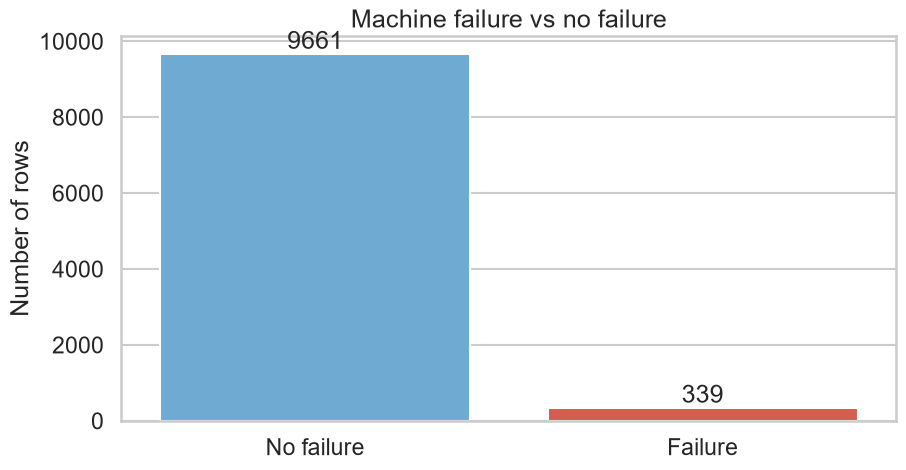

In [3]:
ax = sns.countplot(data=df, x="Failure", hue="Failure", palette=["#5dade2", "#e74c3c"], legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set_title("Machine failure vs no failure"); ax.set_xlabel(""); ax.set_ylabel("Number of rows")
plt.show()

- **Shows:** number of rows in each class. **Useful because** it reveals class balance.
- **Observed:** 9,661 no-failure vs 339 failure rows.
- **Meaning:** failures are rare, so a model that always says "no failure" would be 96.6% accurate but useless. Level 2 must use metrics like recall/F1 and handle imbalance.

## 2. Failure percentage analysis

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


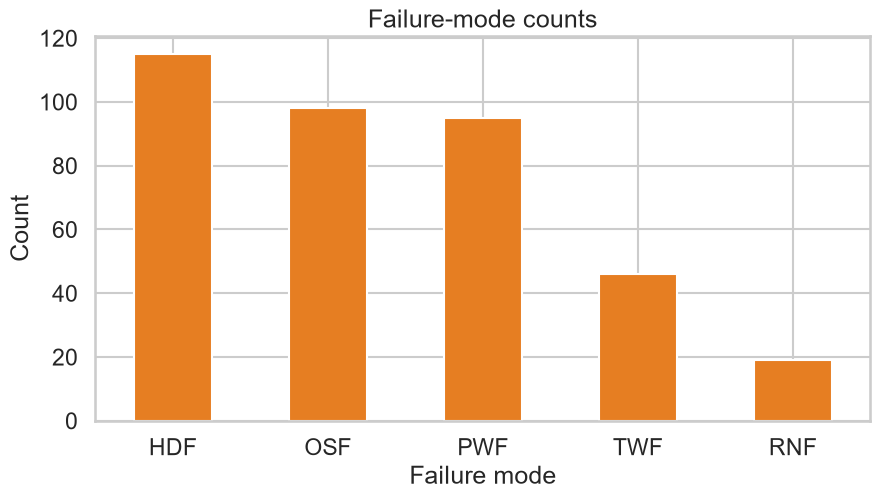

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


In [4]:
print((df[pp.TARGET_COL].value_counts(normalize=True) * 100).round(2))
modes = df[pp.FAILURE_MODE_COLS].sum().sort_values(ascending=False)
ax = modes.plot(kind="bar", color="#e67e22")
ax.set_title("Failure-mode counts"); ax.set_ylabel("Count"); ax.set_xlabel("Failure mode")
plt.xticks(rotation=0); plt.show()
print(modes)

- **Observed:** heat dissipation (HDF) is the most common failure mode, followed by overstrain (OSF) and power (PWF); random failures (RNF) are rarest.
- **Meaning:** most failures are linked to operating conditions (heat, load, power), which suggests the sensor variables should carry useful information.

## 3. Histograms of numerical sensor variables

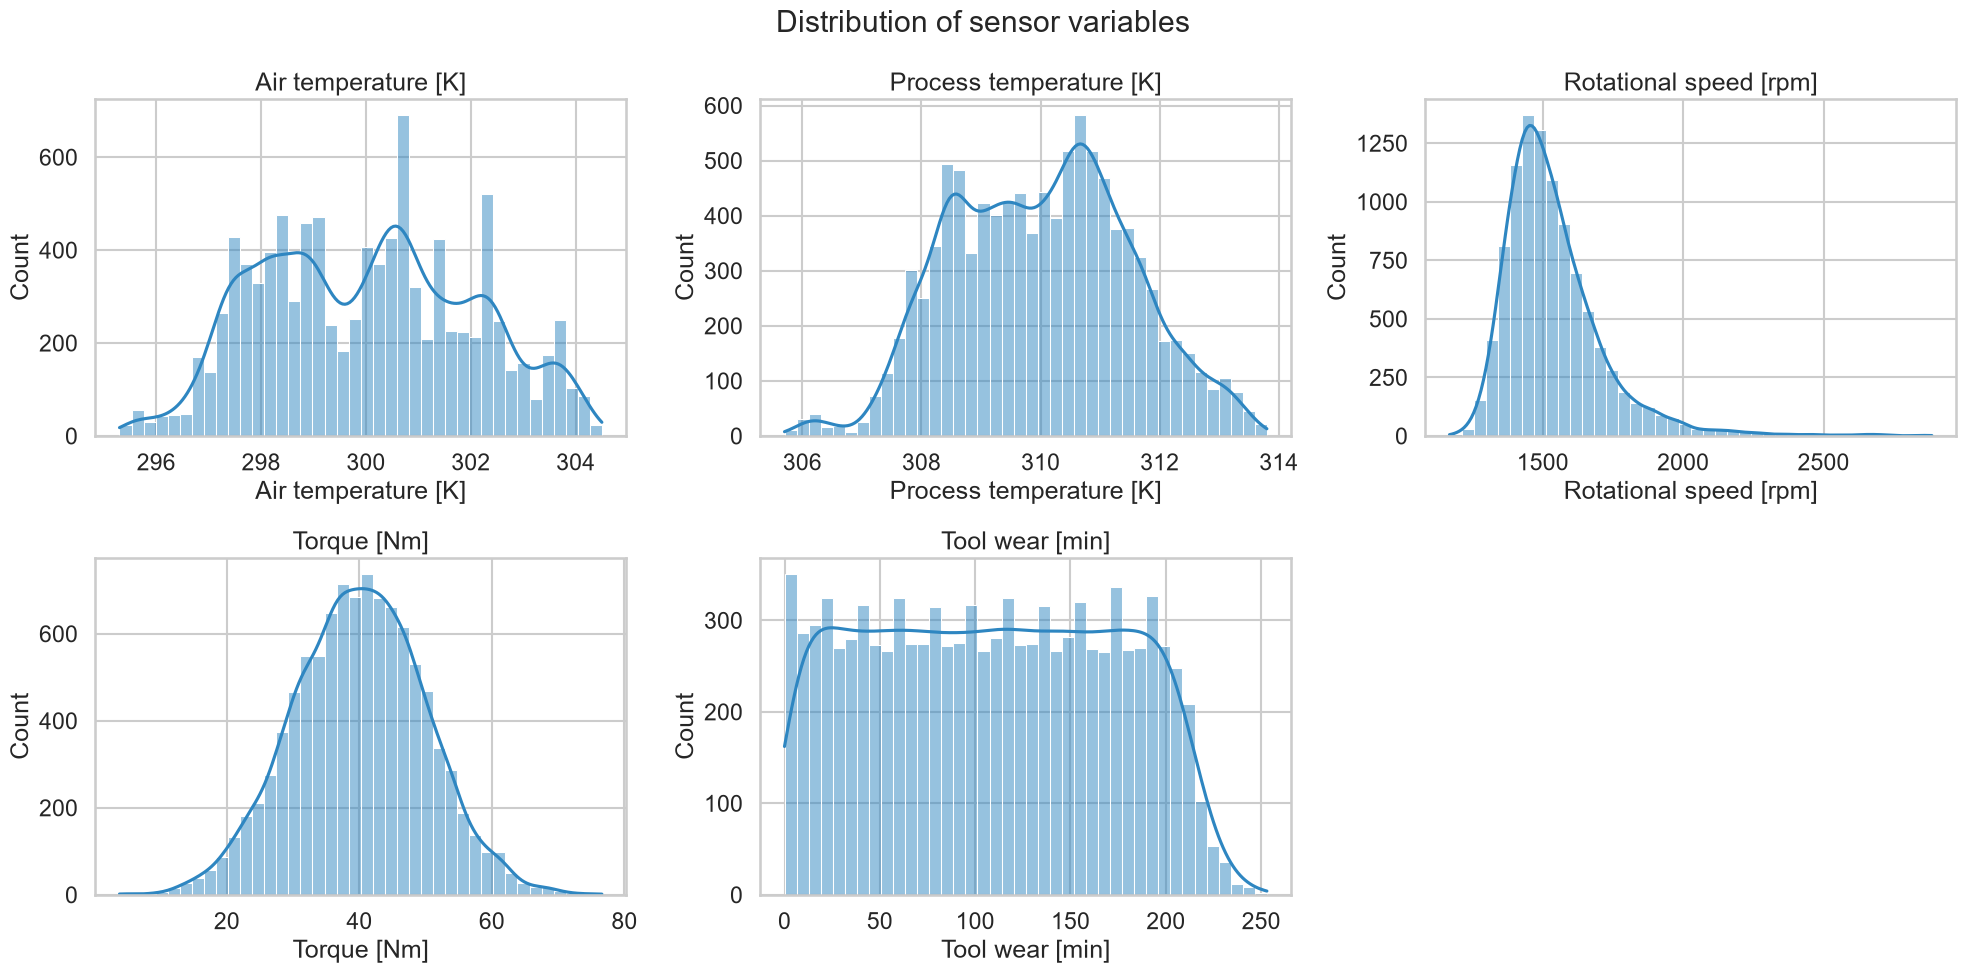

Air temperature [K]        0.11
Process temperature [K]    0.02
Rotational speed [rpm]     1.99
Torque [Nm]               -0.01
Tool wear [min]            0.03
Name: skewness, dtype: float64


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, col in zip(axes.flat, pp.SENSOR_COLS):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color="#2e86c1")
    ax.set_title(col); ax.set_xlabel(col); ax.set_ylabel("Count")
axes.flat[-1].axis("off")
plt.suptitle("Distribution of sensor variables"); plt.tight_layout(); plt.show()
print(df[pp.SENSOR_COLS].skew().round(2).rename("skewness"))

- **Observed:** temperatures are roughly bell-shaped; rotational speed is **right-skewed** (long tail of high speeds); torque is close to normal; tool wear is roughly uniform from 0 to ~200 min then drops.
- **Meaning:** skewed variables suggest non-parametric tests (Mann–Whitney) are safer in Notebook 4.

## 4. Box plots by failure status

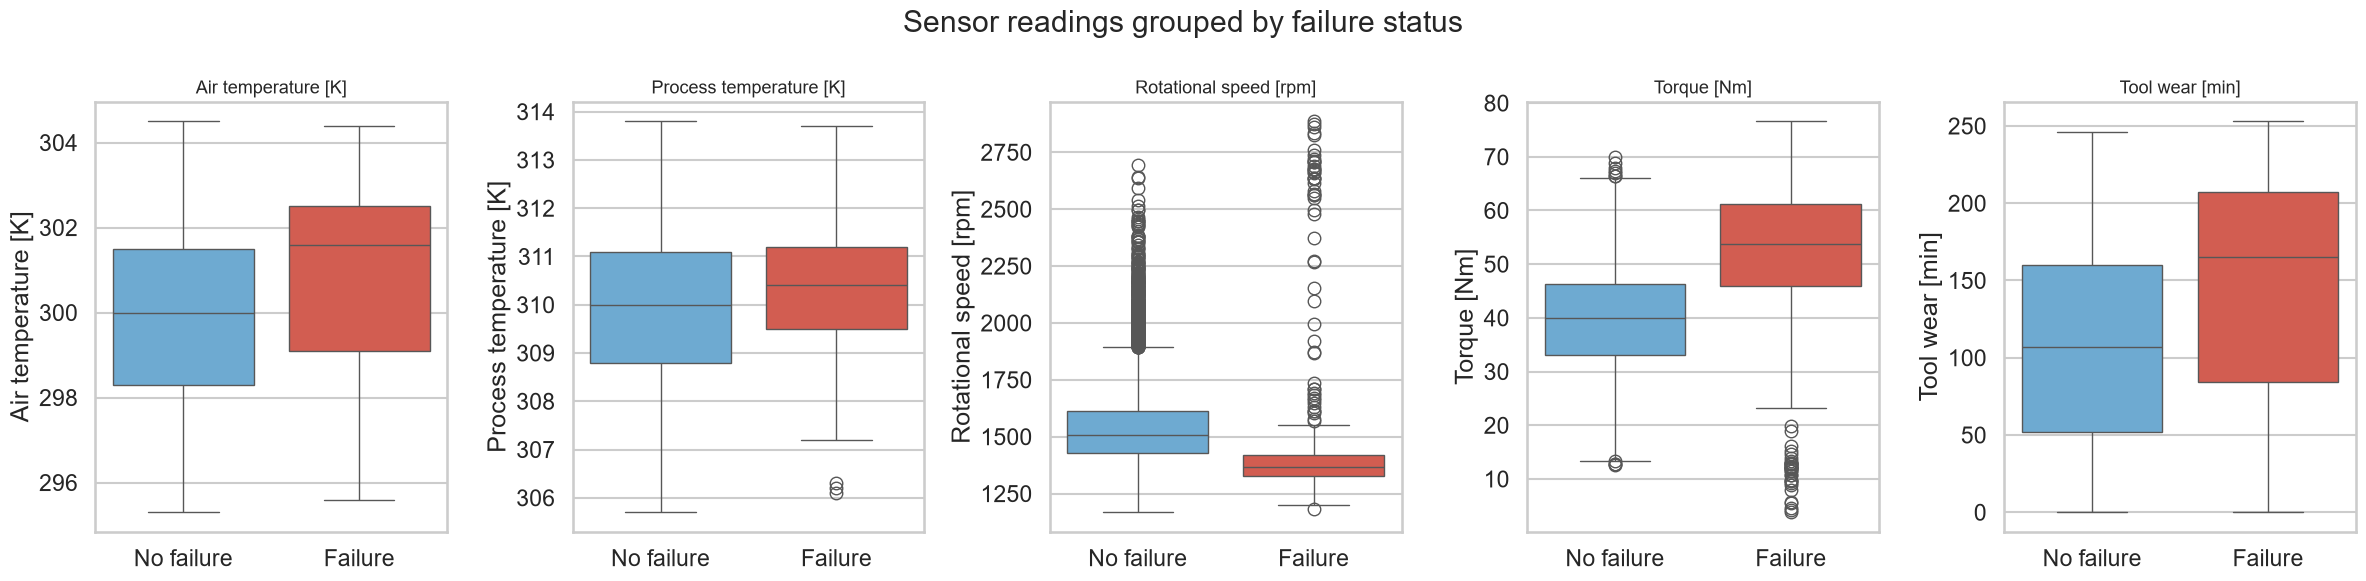

Failure,Failure,No failure
Air temperature [K],301.6,300.0
Process temperature [K],310.4,310.0
Rotational speed [rpm],1365.0,1507.0
Torque [Nm],53.7,39.9
Tool wear [min],165.0,107.0


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(24, 6))
for ax, col in zip(axes, pp.SENSOR_COLS):
    sns.boxplot(data=df, x="Failure", y=col, hue="Failure", ax=ax, palette=["#5dade2", "#e74c3c"], legend=False)
    ax.set_title(col, fontsize=13); ax.set_xlabel("")
plt.suptitle("Sensor readings grouped by failure status"); plt.tight_layout(); plt.show()
df.groupby("Failure")[pp.SENSOR_COLS].median().T

- **Observed (medians):** failures have **higher torque** (~53.7 vs 39.9 Nm), **higher tool wear** (~165 vs 107 min), **lower rotational speed** (~1365 vs 1507 rpm) and slightly higher air temperature. Failure rows also show a much wider spread of speed and torque.
- **Meaning:** heavy load, worn tools and unusual speed/torque combinations are associated with failure.

## 5. Correlation heatmap

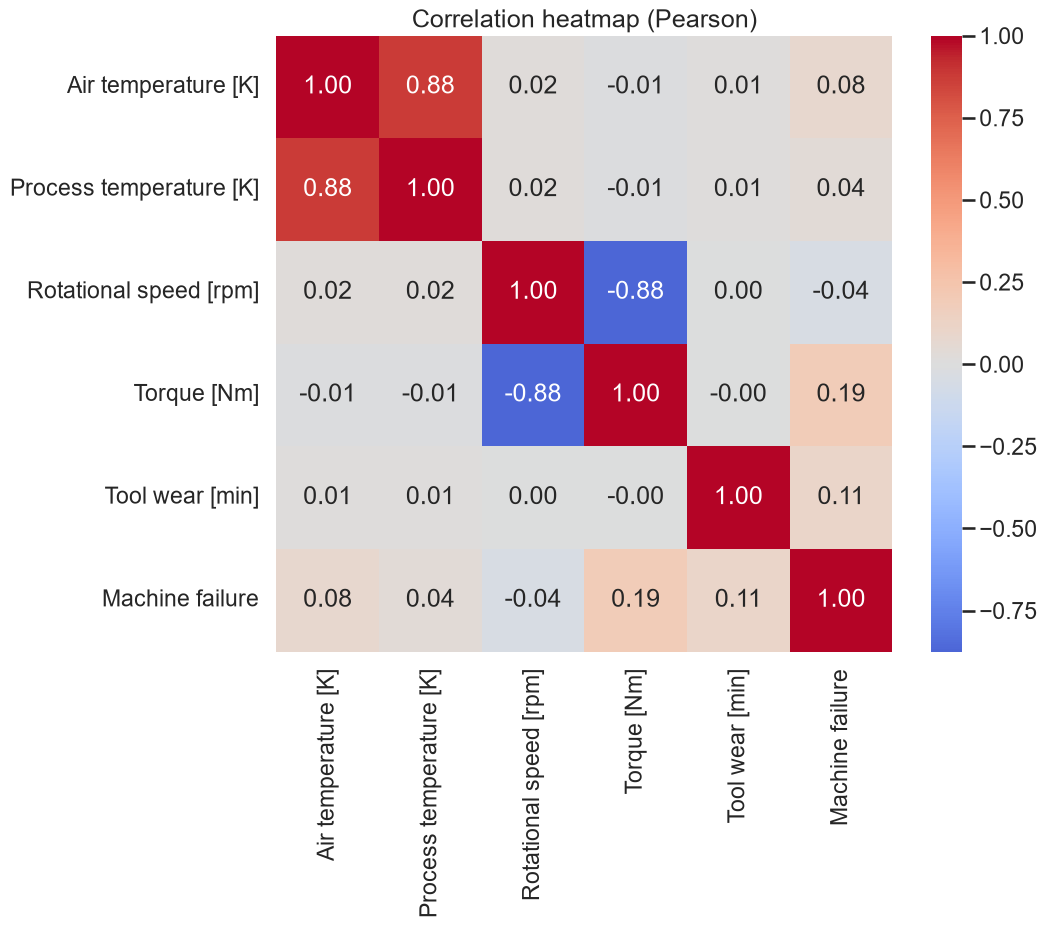

In [7]:
corr = df[pp.SENSOR_COLS + [pp.TARGET_COL]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap (Pearson)"); plt.show()

- **Observed:** air and process temperature are strongly correlated (~0.88); rotational speed and torque are strongly **negatively** correlated (~−0.88). Each single variable has only a weak linear correlation with failure.
- **Meaning:** failures are not explained by one variable alone — combinations matter. Correlation is linear only and does not imply causation.

## 6. Air temperature vs process temperature

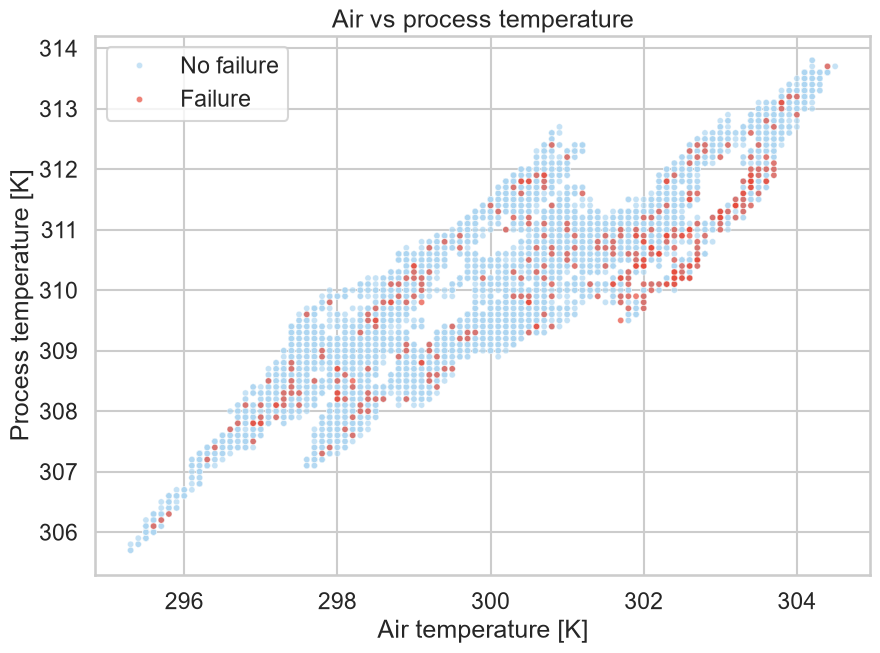

In [8]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df.sort_values(pp.TARGET_COL), x="Air temperature [K]", y="Process temperature [K]",
                hue="Failure", palette={"No failure": "#aed6f1", "Failure": "#e74c3c"}, s=20, alpha=0.7)
plt.title("Air vs process temperature"); plt.legend(title=""); plt.show()

- **Observed:** the two temperatures rise together. Failures appear more at higher air temperatures.
- **Meaning:** the *gap* between the two temperatures may matter (heat dissipation) — this motivates the `temp_diff_K` feature in Notebook 5.

## 7. Rotational speed vs torque

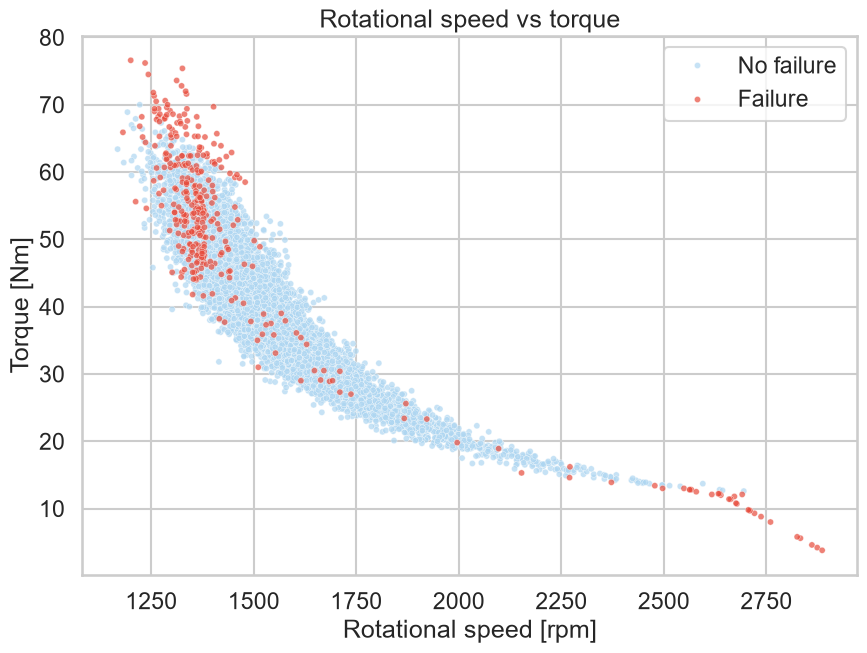

In [9]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df.sort_values(pp.TARGET_COL), x="Rotational speed [rpm]", y="Torque [Nm]",
                hue="Failure", palette={"No failure": "#aed6f1", "Failure": "#e74c3c"}, s=20, alpha=0.7)
plt.title("Rotational speed vs torque"); plt.legend(title=""); plt.show()

- **Observed:** a clear curved negative relationship. Failures cluster at the **extremes**: low speed + high torque (overload) and high speed + low torque.
- **Meaning:** the product speed × torque (mechanical power) is likely a useful feature → created in Notebook 5.

## 8. Tool wear vs failure

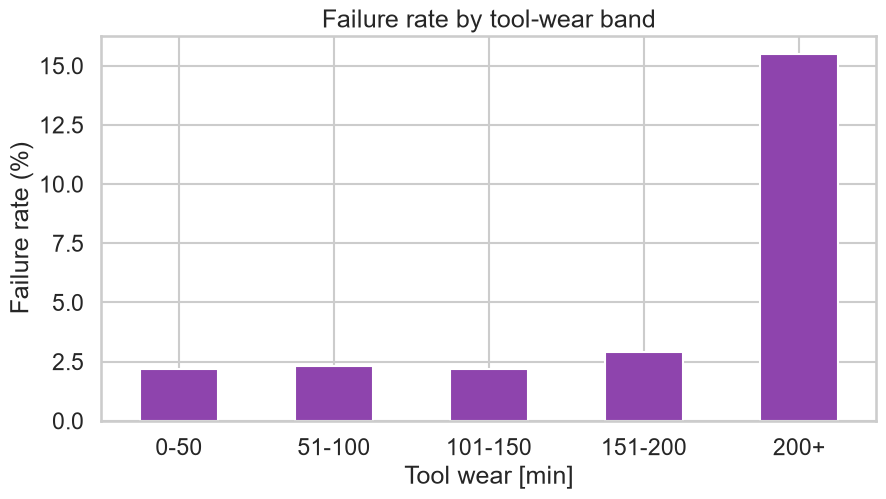

,count,failure_%
Tool wear [min],,
0-50,2396,2.17
51-100,2271,2.33
101-150,2295,2.18
151-200,2276,2.90
200+,762,15.49


In [10]:
bands = pd.cut(df["Tool wear [min]"], bins=[-0.1, 50, 100, 150, 200, np.inf],
               labels=["0-50", "51-100", "101-150", "151-200", "200+"])
rate = df.groupby(bands, observed=True)[pp.TARGET_COL].agg(["count", "mean"])
rate["failure_%"] = (rate["mean"] * 100).round(2)
ax = rate["failure_%"].plot(kind="bar", color="#8e44ad")
ax.set_title("Failure rate by tool-wear band"); ax.set_xlabel("Tool wear [min]"); ax.set_ylabel("Failure rate (%)")
plt.xticks(rotation=0); plt.show()
rate[["count", "failure_%"]]

- **Observed:** failure rate is about 2–3% up to 200 min and jumps to about **15%** above 200 min.
- **Meaning:** tool replacement policy around 200 minutes could prevent many failures (association, not proven cause).

## 9. Failure distribution by product type

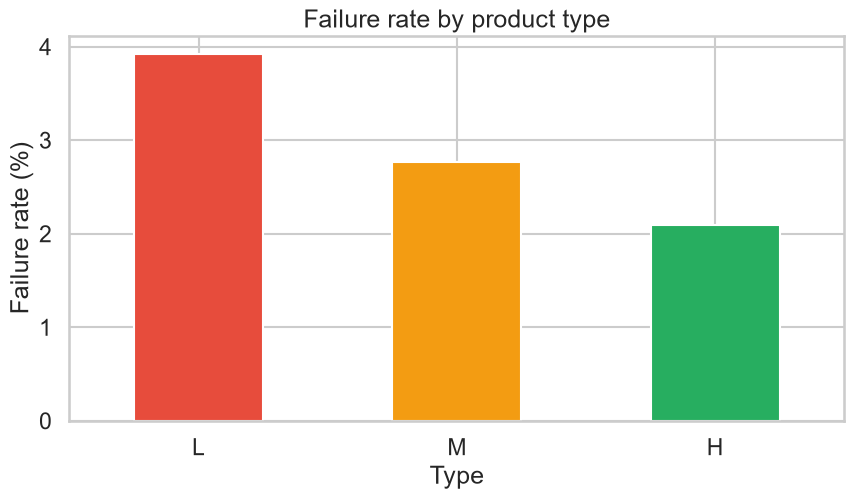

,count,sum,mean,failure_%
Type,,,,
L,6000,235,0.039167,3.92
M,2997,83,0.027694,2.77
H,1003,21,0.020937,2.09


In [11]:
type_rate = df.groupby("Type")[pp.TARGET_COL].agg(["count", "sum", "mean"]).reindex(["L", "M", "H"])
type_rate["failure_%"] = (type_rate["mean"] * 100).round(2)
ax = type_rate["failure_%"].plot(kind="bar", color=["#e74c3c", "#f39c12", "#27ae60"])
ax.set_title("Failure rate by product type"); ax.set_ylabel("Failure rate (%)"); ax.set_xlabel("Type")
plt.xticks(rotation=0); plt.show()
type_rate

- **Observed:** L ≈ 3.9%, M ≈ 2.8%, H ≈ 2.1%.
- **Meaning:** lower-quality products fail more often; tested formally in Notebook 4.

## 10. Pair plot (small subset, sampled)

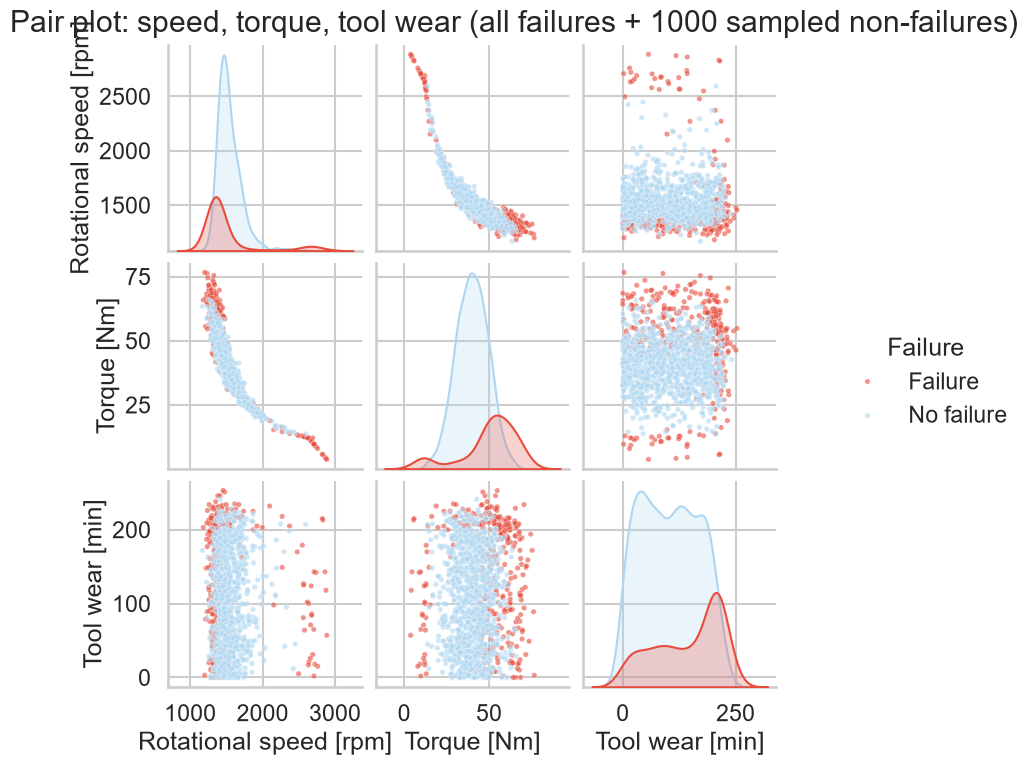

In [12]:
sample = pd.concat([df[df[pp.TARGET_COL] == 1], df[df[pp.TARGET_COL] == 0].sample(1000, random_state=42)])
g = sns.pairplot(sample[["Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]", "Failure"]],
                 hue="Failure", palette={"No failure": "#aed6f1", "Failure": "#e74c3c"},
                 plot_kws={"s": 15, "alpha": 0.6})
g.fig.suptitle("Pair plot: speed, torque, tool wear (all failures + 1000 sampled non-failures)", y=1.02)
plt.show()

- **Note:** non-failures were sampled (seed 42) so the plot stays readable; this changes the class proportions in the picture only.
- **Observed:** failures separate best in the speed–torque panel and at high tool wear.

## 11–12. Conclusion and limitations
**Potential relationships:** high torque, low speed (or extreme speed/torque combos), high tool wear (>200 min), higher air temperature and Type L are associated with failure.

**Limitations:**
- Synthetic dataset; real factories may behave differently.
- Only ~3.4% failures → patterns among failures are based on 339 rows.
- No timestamps → no trends over time.
- All findings are **associations, not causes**.